In [27]:
import pandas as pd
import numpy as np
from mlxtend.frequent_patterns import apriori, association_rules
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder

In [28]:
data = pd.read_excel('Online Retail.xlsx')

In [29]:
data.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [30]:
data.shape

(541909, 8)

In [31]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [32]:
data_clean = data[
    data["Description"].notna()
    & (data["Description"].astype(str).str.strip() != "")
    & (~data["InvoiceNo"].astype(str).str.startswith("C"))
    & (data["Quantity"] > 0)
    & (data["CustomerID"].notna())
].copy()

In [33]:
print(data_clean.shape)
print(data_clean.info())

(397924, 8)
<class 'pandas.core.frame.DataFrame'>
Index: 397924 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    397924 non-null  object        
 1   StockCode    397924 non-null  object        
 2   Description  397924 non-null  object        
 3   Quantity     397924 non-null  int64         
 4   InvoiceDate  397924 non-null  datetime64[ns]
 5   UnitPrice    397924 non-null  float64       
 6   CustomerID   397924 non-null  float64       
 7   Country      397924 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 27.3+ MB
None


In [34]:
for nama, df in [('Sebelum', data), ('Sesudah', data_clean)]:
    print(nama, '| baris:', len(df), '| invoice:', df['InvoiceNo'].nunique(), '| pelanggan:', df['CustomerID'].nunique())

Sebelum | baris: 541909 | invoice: 25900 | pelanggan: 4372
Sesudah | baris: 397924 | invoice: 18536 | pelanggan: 4339


In [35]:
kolom_relevan = ['CustomerID', 'InvoiceNo', 'InvoiceDate', 'Description']
data_seq = data_clean[kolom_relevan].copy()
data_seq['CustomerID'] = data_seq['CustomerID'].astype(int)
data_seq['InvoiceNo'] = data_seq['InvoiceNo'].astype(str)
data_seq['Description'] = data_seq['Description'].astype(str).str.strip().str.upper()
data_seq.head()

,CustomerID,InvoiceNo,InvoiceDate,Description
0,17850,536365,2010-12-01 08:26:00,WHITE HANGING HEART T-LIGHT HOLDER
1,17850,536365,2010-12-01 08:26:00,WHITE METAL LANTERN
2,17850,536365,2010-12-01 08:26:00,CREAM CUPID HEARTS COAT HANGER
3,17850,536365,2010-12-01 08:26:00,KNITTED UNION FLAG HOT WATER BOTTLE
4,17850,536365,2010-12-01 08:26:00,RED WOOLLY HOTTIE WHITE HEART.


In [36]:
data_seq = data_seq.sort_values(['CustomerID', 'InvoiceDate', 'InvoiceNo'])

invoice_itemset = (
    data_seq.groupby(['CustomerID', 'InvoiceNo'], sort=False)
    .agg(InvoiceDate=('InvoiceDate', 'min'),
         Items=('Description', lambda s: sorted(set(s))))
    .reset_index()
    .sort_values(['CustomerID', 'InvoiceDate', 'InvoiceNo'])
)
invoice_itemset.head()

,CustomerID,InvoiceNo,InvoiceDate,Items
0,12346,541431,2011-01-18 10:01:00,[MEDIUM CERAMIC TOP STORAGE JAR]
1,12347,537626,2010-12-07 14:57:00,"[3D DOG PICTURE PLAYING CARDS, AIRLINE BAG VIN..."
2,12347,542237,2011-01-26 14:30:00,"[3D DOG PICTURE PLAYING CARDS, 60 TEATIME FAIR..."
3,12347,549222,2011-04-07 10:43:00,"[3D SHEET OF CAT STICKERS, 3D SHEET OF DOG STI..."
4,12347,556201,2011-06-09 13:01:00,"[3D DOG PICTURE PLAYING CARDS, AIRLINE BAG VIN..."


In [37]:
sequences_db = invoice_itemset.groupby('CustomerID')['Items'].apply(list)
sequences = sequences_db.tolist()

print('Jumlah sequence (pelanggan):', len(sequences))
print('Contoh sequence pelanggan', sequences_db.index[0], '(3 itemset pertama):')
for itemset in sequences[0][:3]:
    print('  ', itemset[:5], '...' if len(itemset) > 5 else '')

panjang = pd.Series([len(s) for s in sequences])
print()
print('Statistik jumlah invoice (itemset) per pelanggan:')
print(panjang.describe())

Jumlah sequence (pelanggan): 4339
Contoh sequence pelanggan 12346 (3 itemset pertama):
   ['MEDIUM CERAMIC TOP STORAGE JAR'] 

Statistik jumlah invoice (itemset) per pelanggan:
count    4339.000000
mean        4.271952
std         7.705493
min         1.000000
25%         1.000000
50%         2.000000
75%         5.000000
max       210.000000
dtype: float64


In [38]:
import time
from collections import Counter
from prefixspan import PrefixSpan

sequences_flat = [[item for itemset in seq for item in itemset] for seq in sequences]
n_cust = len(sequences_flat)

def prepare_sequences(min_support_rel):
    min_count = int(np.ceil(min_support_rel * n_cust))
    cnt = Counter(item for seq in sequences_flat for item in set(seq))
    frequent_items = {i for i, c in cnt.items() if c >= min_count}
    seqs = [[i for i in s if i in frequent_items] for s in sequences_flat]
    seqs = [s for s in seqs if s]
    return seqs, min_count

def mine_prefixspan(min_support_rel, minlen=2, maxlen=3):
    seqs, min_count = prepare_sequences(min_support_rel)

    ps = PrefixSpan(seqs)
    ps.minlen = minlen
    ps.maxlen = maxlen
    hasil = ps.frequent(min_count)

    df = pd.DataFrame(hasil, columns=['support_count', 'pattern'])
    df['support'] = df['support_count'] / n_cust
    df['length'] = df['pattern'].apply(len)
    df['pattern_str'] = df['pattern'].apply(lambda p: ' -> '.join(p))
    return (df.sort_values(['support_count', 'length'], ascending=[False, True])
              .reset_index(drop=True))

In [39]:
percobaan = []
hasil_per_support = {}
for ms in [0.01, 0.02, 0.03, 0.05]:
    t0 = time.time()
    df_ms = mine_prefixspan(ms)
    hasil_per_support[ms] = df_ms
    percobaan.append({'min_support': ms,
                      'min_count (pelanggan)': int(np.ceil(ms * n_cust)),
                      'jumlah pola': len(df_ms),
                      'waktu (detik)': round(time.time() - t0, 1)})
pd.DataFrame(percobaan)

,min_support,min_count (pelanggan),jumlah pola,waktu (detik)
0,0.01,44,75526,101.9
1,0.02,87,5512,17.8
2,0.03,131,888,6.6
3,0.05,217,71,1.3


0.05 dipilih karena kita tidak perlu pola yang terlalu banyak karena hanya mengambil top 3 dalam analisis dan meningkatkan min support juga membantu memastikan polanya sering terjadi dan ringkas sehingga mudah dibaca.

In [40]:
MIN_SUPPORT = 0.05
patterns = hasil_per_support[MIN_SUPPORT]
print('Jumlah pola:', len(patterns))
patterns[['pattern_str', 'length', 'support_count', 'support']].head(20)

Jumlah pola: 71


,pattern_str,length,support_count,support
0,WHITE HANGING HEART T-LIGHT HOLDER -> WHITE HA...,2,405,0.093339
1,REGENCY CAKESTAND 3 TIER -> REGENCY CAKESTAND ...,2,330,0.076054
2,PAPER CHAIN KIT 50'S CHRISTMAS -> PAPER CHAIN ...,2,321,0.073980
3,GREEN REGENCY TEACUP AND SAUCER -> ROSES REGEN...,2,318,0.073289
4,JUMBO BAG RED RETROSPOT -> JUMBO BAG RED RETRO...,2,312,0.071906
5,REGENCY CAKESTAND 3 TIER -> ROSES REGENCY TEAC...,2,299,0.068910
6,GREEN REGENCY TEACUP AND SAUCER -> PINK REGENC...,2,294,0.067758
7,LUNCH BAG CARS BLUE -> LUNCH BAG RED RETROSPOT,2,293,0.067527
8,RED HANGING HEART T-LIGHT HOLDER -> WHITE HANG...,2,293,0.067527
9,HEART OF WICKER LARGE -> HEART OF WICKER SMALL,2,292,0.067297


In [41]:
seqs, min_count = prepare_sequences(MIN_SUPPORT)

ps = PrefixSpan(seqs)
ps.minlen, ps.maxlen = 1, 3
semua = ps.frequent(min_count)

supp = {tuple(p): c for c, p in semua}   

baris = []
for c, p in semua:
    if len(p) >= 2:
        awal = tuple(p[:-1])           
        baris.append({
            'pattern_str': ' -> '.join(p),
            'support_count': c,
            'support': c / n_cust,
            'confidence': c / supp[awal],
        })

rules_df = (pd.DataFrame(baris)
              .sort_values('support_count', ascending=False)
              .reset_index(drop=True))
rules_df.head(10)

,pattern_str,support_count,support,confidence
0,WHITE HANGING HEART T-LIGHT HOLDER -> WHITE HA...,405,0.093339,0.473131
1,REGENCY CAKESTAND 3 TIER -> REGENCY CAKESTAND ...,330,0.076054,0.374574
2,PAPER CHAIN KIT 50'S CHRISTMAS -> PAPER CHAIN ...,321,0.073980,0.523654
3,GREEN REGENCY TEACUP AND SAUCER -> ROSES REGEN...,318,0.073289,0.821705
4,JUMBO BAG RED RETROSPOT -> JUMBO BAG RED RETRO...,312,0.071906,0.491339
5,REGENCY CAKESTAND 3 TIER -> ROSES REGENCY TEAC...,299,0.068910,0.339387
6,GREEN REGENCY TEACUP AND SAUCER -> PINK REGENC...,294,0.067758,0.759690
7,LUNCH BAG CARS BLUE -> LUNCH BAG RED RETROSPOT,293,0.067527,0.611691
8,RED HANGING HEART T-LIGHT HOLDER -> WHITE HANG...,293,0.067527,0.761039
9,HEART OF WICKER LARGE -> HEART OF WICKER SMALL,292,0.067297,0.602062


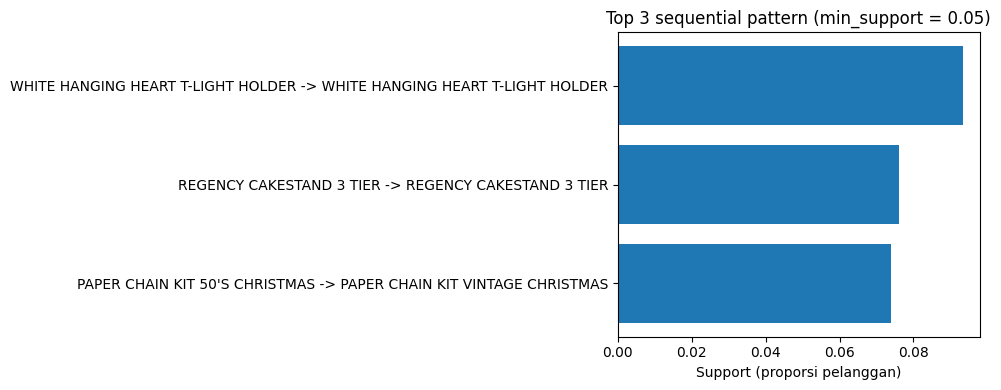

In [42]:
top3 = patterns.head(3).iloc[::-1]

plt.figure(figsize=(10, 4))
plt.barh(top3['pattern_str'], top3['support'])
plt.xlabel('Support (proporsi pelanggan)')
plt.title(f'Top 3 sequential pattern (min_support = {MIN_SUPPORT})')
plt.tight_layout()
plt.show()

Terlihat 2 dari 3 membeli hal yang sama artinya banyak pelanggan yang memiliki pola sequential cenderung membeli hal yang sama dan untuk pasangan no 3 Paper chain kit 50's christmas dan paper chain kit vintage christmas sama sama untuk natal/christmas hal ini karena pada saat natal orang orang tidak hanya membeli satu hiasan namun banyak untuk menghias lingkungan mereka.

Secara eksplisit no 1, no 2, no 3  memiliki persentase pelanggan memiliki pola sequential adalah sekitar 9%,8%, dan 7%.

yang bisa dilakukan toko retail adalah memberi bundle ke produk yang jenisnya sama agar pelanggan tertarik untuk pergi ke toko dan pada saat musim tertentu seperti natal membeli bundling hiasan natal agar menjadi lebih efisien bagi pelanggan untuk membeli produknya dan makin tertarik untuk membeli, bisa juga dengan memberi diskon untuk pelanggan setia karena persentase yang besar juga bisa berarti pembelian berulang dari customer.